In [ ]:
from cargar_datos import cargarDatos
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.ticker as ticker
import pandas as pd


# Cargamos los datos

In [13]:
df = cargarDatos()
df.head()

,tipo_credito,fecha_prestamo,capital_prestado,plazo_meses,edad_cliente,tipo_laboral,salario_cliente,total_otros_prestamos,cuota_pactada,puntaje,...,saldo_mora,saldo_total,saldo_principal,saldo_mora_codeudor,creditos_sectorFinanciero,creditos_sectorCooperativo,creditos_sectorReal,promedio_ingresos_datacredito,tendencia_ingresos,Pago_atiempo
0,7,2024-12-21 11:31:35,3692160.0,10,42,Independiente,8000000,2500000,341296,88.768094,...,0.0,51258.0,51258.0,0.0,5,0,0,908526.0,Estable,1
1,4,2025-04-22 09:47:35,840000.0,6,60,Empleado,3000000,2000000,124876,95.227787,...,0.0,8673.0,8673.0,0.0,0,0,2,939017.0,Creciente,1
2,9,2026-01-08 12:22:40,5974028.4,10,36,Independiente,4036000,829000,529554,47.613894,...,0.0,18702.0,18702.0,0.0,3,0,0,NaN,NaN,0
3,4,2025-08-04 12:04:10,1671240.0,6,48,Empleado,1524547,498000,252420,95.227787,...,0.0,15782.0,15782.0,0.0,3,0,0,1536193.0,Creciente,1
4,9,2025-04-26 11:24:26,2781636.0,11,44,Empleado,5000000,4000000,217037,95.227787,...,0.0,204804.0,204804.0,0.0,3,0,1,933473.0,Creciente,1


# 2 Exploracion de datos

## 2.1 Revision de nulos

In [14]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10763 entries, 0 to 10762
Data columns (total 23 columns):
 #   Column                         Non-Null Count  Dtype         
---  ------                         --------------  -----         
 0   tipo_credito                   10763 non-null  int64         
 1   fecha_prestamo                 10763 non-null  datetime64[ns]
 2   capital_prestado               10763 non-null  float64       
 3   plazo_meses                    10763 non-null  int64         
 4   edad_cliente                   10763 non-null  int64         
 5   tipo_laboral                   10763 non-null  object        
 6   salario_cliente                10763 non-null  int64         
 7   total_otros_prestamos          10763 non-null  int64         
 8   cuota_pactada                  10763 non-null  int64         
 9   puntaje                        10763 non-null  float64       
 10  puntaje_datacredito            10757 non-null  float64       
 11  cant_creditosvi

## 2.2 Convertire todos los valores similares a null en null

In [15]:
df = df.replace(["NA", "N/A", "null", "NULL", "?", "Sin dato"], np.nan)


## 2.1 Tipo de variables

### Variables categóricas

    Ordinales
    - tipo_credito (Politómico)
    - fecha_prestamo (Politómico)

    Nominales
    - tipo_laboral (Dicotómico)
    - tendencia_ingresos (Politómico)

### Variables numéricas

    Continuas
    - capital_prestado
    - salario_cliente
    - total_otros_prestamos
    - puntaje
    - puntaje_datacredito
    - saldo_mora
    - saldo_total
    - saldo_principal
    - Promedio_ingresos_datacredito

    Discretas
    - plazo_meses
    - edad_cliente
    - cuota_pactada
    - cant_creditosvigentes
    - huella_consulta
    - creditos_sectorFinanciero
    - creditos_sectorCooperativo
    - creditos_sectorReal

## 2.3 Eliminacion variables irrelevantes

Fecha prestamo y plazo meses, no son relevantes para los objetivos iniciales de exploración, con cuota pactada y capital prestado se puede saber el plazo de pago.

In [16]:
df = df.drop(columns=["fecha_prestamo","plazo_meses"])

## 2.4 Conversión del tipo de datos a category
Se convierten las variables categoricas tipo object a category

In [17]:
df["tipo_credito"] = df["tipo_credito"].astype("category")
df["tipo_laboral"] = df["tipo_laboral"].astype("category")
df["tendencia_ingresos"] = df["tendencia_ingresos"].astype("category")

In [18]:
# verificamos como quedo
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10763 entries, 0 to 10762
Data columns (total 21 columns):
 #   Column                         Non-Null Count  Dtype   
---  ------                         --------------  -----   
 0   tipo_credito                   10763 non-null  category
 1   capital_prestado               10763 non-null  float64 
 2   edad_cliente                   10763 non-null  int64   
 3   tipo_laboral                   10763 non-null  category
 4   salario_cliente                10763 non-null  int64   
 5   total_otros_prestamos          10763 non-null  int64   
 6   cuota_pactada                  10763 non-null  int64   
 7   puntaje                        10763 non-null  float64 
 8   puntaje_datacredito            10757 non-null  float64 
 9   cant_creditosvigentes          10763 non-null  int64   
 10  huella_consulta                10763 non-null  int64   
 11  saldo_mora                     10607 non-null  float64 
 12  saldo_total                    1

# 3 EDA

## 3.1 Analisis Univariable

### 3.1.1 Analizamos las variables numéricas

In [19]:
df.describe()

,capital_prestado,edad_cliente,salario_cliente,total_otros_prestamos,cuota_pactada,puntaje,puntaje_datacredito,cant_creditosvigentes,huella_consulta,saldo_mora,saldo_total,saldo_principal,saldo_mora_codeudor,creditos_sectorFinanciero,creditos_sectorCooperativo,creditos_sectorReal,promedio_ingresos_datacredito,Pago_atiempo
count,1.076300e+04,10763.000000,1.076300e+04,1.076300e+04,1.076300e+04,10763.000000,10757.000000,10763.000000,10763.000000,10607.000000,1.060700e+04,1.035800e+04,10173.000000,10763.000000,10763.000000,10763.000000,7.833000e+03,10763.000000
mean,2.434315e+06,43.948620,1.721643e+07,6.238870e+06,2.436174e+05,91.170036,780.790834,5.726749,4.228561,7.746017,4.593741e+04,4.034617e+04,0.260002,2.779987,0.269813,1.302704,2.005157e+06,0.952523
std,1.909643e+06,15.060877,3.554767e+08,1.184183e+08,2.104937e+05,16.465441,104.878031,3.977162,3.064683,225.955117,1.062698e+05,7.124244e+04,21.772917,2.748807,0.716471,1.824430,2.144116e+06,0.212668
min,3.600000e+05,19.000000,0.000000e+00,0.000000e+00,2.394400e+04,-38.009990,-7.000000,0.000000,0.000000,0.000000,0.000000e+00,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000e+00,0.000000
25%,1.224831e+06,33.000000,2.000000e+06,5.000000e+05,1.210415e+05,95.227787,757.000000,3.000000,2.000000,0.000000,2.898000e+03,2.690000e+03,0.000000,1.000000,0.000000,0.000000,9.251570e+05,1.000000
50%,1.921920e+06,42.000000,3.000000e+06,1.000000e+06,1.828630e+05,95.227787,791.000000,5.000000,4.000000,0.000000,1.617800e+04,1.444250e+04,0.000000,2.000000,0.000000,1.000000,1.204496e+06,1.000000
75%,3.084840e+06,53.000000,4.875808e+06,2.000000e+06,2.878335e+05,95.227787,825.000000,8.000000,6.000000,0.000000,5.298200e+04,4.763225e+04,0.000000,4.000000,0.000000,2.000000,2.231859e+06,1.000000
max,4.144415e+07,123.000000,2.200000e+10,6.787675e+09,3.816752e+06,95.227787,999.000000,62.000000,29.000000,12534.000000,5.116066e+06,1.562285e+06,2145.000000,51.000000,13.000000,25.000000,3.810658e+07,1.000000


Tenemos edades con números superiores a 100, lo cual no es posible, se actualizará a todos los valores no viables, por el valor promedio

In [20]:
# 1. Calcular el promedio usando SOLO las edades válidas (<= 100)
promedio_edad = round(df.loc[df['edad_cliente'] <= 100, 'edad_cliente'].mean())
#print (promedio_edad)

df.loc[df['edad_cliente'] > 100, 'edad_cliente'] = promedio_edad
df.describe()

,capital_prestado,edad_cliente,salario_cliente,total_otros_prestamos,cuota_pactada,puntaje,puntaje_datacredito,cant_creditosvigentes,huella_consulta,saldo_mora,saldo_total,saldo_principal,saldo_mora_codeudor,creditos_sectorFinanciero,creditos_sectorCooperativo,creditos_sectorReal,promedio_ingresos_datacredito,Pago_atiempo
count,1.076300e+04,10763.000000,1.076300e+04,1.076300e+04,1.076300e+04,10763.000000,10757.000000,10763.000000,10763.000000,10607.000000,1.060700e+04,1.035800e+04,10173.000000,10763.000000,10763.000000,10763.000000,7.833000e+03,10763.000000
mean,2.434315e+06,42.847812,1.721643e+07,6.238870e+06,2.436174e+05,91.170036,780.790834,5.726749,4.228561,7.746017,4.593741e+04,4.034617e+04,0.260002,2.779987,0.269813,1.302704,2.005157e+06,0.952523
std,1.909643e+06,11.863768,3.554767e+08,1.184183e+08,2.104937e+05,16.465441,104.878031,3.977162,3.064683,225.955117,1.062698e+05,7.124244e+04,21.772917,2.748807,0.716471,1.824430,2.144116e+06,0.212668
min,3.600000e+05,19.000000,0.000000e+00,0.000000e+00,2.394400e+04,-38.009990,-7.000000,0.000000,0.000000,0.000000,0.000000e+00,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000e+00,0.000000
25%,1.224831e+06,33.000000,2.000000e+06,5.000000e+05,1.210415e+05,95.227787,757.000000,3.000000,2.000000,0.000000,2.898000e+03,2.690000e+03,0.000000,1.000000,0.000000,0.000000,9.251570e+05,1.000000
50%,1.921920e+06,42.000000,3.000000e+06,1.000000e+06,1.828630e+05,95.227787,791.000000,5.000000,4.000000,0.000000,1.617800e+04,1.444250e+04,0.000000,2.000000,0.000000,1.000000,1.204496e+06,1.000000
75%,3.084840e+06,52.000000,4.875808e+06,2.000000e+06,2.878335e+05,95.227787,825.000000,8.000000,6.000000,0.000000,5.298200e+04,4.763225e+04,0.000000,4.000000,0.000000,2.000000,2.231859e+06,1.000000
max,4.144415e+07,69.000000,2.200000e+10,6.787675e+09,3.816752e+06,95.227787,999.000000,62.000000,29.000000,12534.000000,5.116066e+06,1.562285e+06,2145.000000,51.000000,13.000000,25.000000,3.810658e+07,1.000000


### 3.1.2 Analizamos las variables categoricas
Para las variables categoricas verificaremos si hay nulos

In [21]:
df.tipo_laboral.value_counts()

tipo_laboral
Empleado         6754
Independiente    4009
Name: count, dtype: int64

Vemos que hay solo 2 tipos y no se encuentran muy desbalanceadas

In [22]:
df.tipo_credito.value_counts()

tipo_credito
4     7747
9     2876
10     116
6       21
7        2
68       1
Name: count, dtype: int64

vemos que hay tipos de credito que tienen muy poco uso, puede ser error de tipeo, se eliminaran los tipos 7 y 68

In [23]:
df = df[~df['tipo_credito'].isin([7, 68])] # solo se queda con las categorias que no son 7 ni 68
df['tipo_credito'] = df['tipo_credito'].cat.remove_unused_categories() # elimina los tipos de crédio de la memoria interna
df.tipo_credito.value_counts()

tipo_credito
4     7747
9     2876
10     116
6       21
Name: count, dtype: int64

In [24]:
df.tendencia_ingresos.value_counts(50)

tendencia_ingresos
Creciente      0.676076
Decreciente    0.164900
Estable        0.151616
0              0.000894
8315           0.000766
1000000        0.000511
9147           0.000255
-101368        0.000128
-70715         0.000128
-164315        0.000128
-435177        0.000128
-224714        0.000128
-702927        0.000128
-566272        0.000128
5697           0.000128
3978           0.000128
-4105          0.000128
-288           0.000128
-28589         0.000128
9090           0.000128
10808          0.000128
15090          0.000128
24702          0.000128
31837          0.000128
52862          0.000128
54683          0.000128
15245          0.000128
17181          0.000128
22363          0.000128
22832          0.000128
82657          0.000128
77975          0.000128
75761          0.000128
65988          0.000128
86286          0.000128
122727         0.000128
146918         0.000128
158042         0.000128
417087         0.000128
209090         0.000128
173031         0.0001

Tenemos un problema de calidad de datos en la variable tendencia_ingresos por lo que tenemos que corregir esta variable dejando las categorias esperadas (Creciente, Decreciente, Estable) y eliminar los datos numericos que no corresponden a una variable categorica

In [25]:
categorias_validas = ["Creciente", "Decreciente", "Estable"]
df["tendencia_ingresos"] = df["tendencia_ingresos"].where(
    df["tendencia_ingresos"].isin(categorias_validas), 
    np.nan
)

df["tendencia_ingresos"] = df["tendencia_ingresos"].astype("category")
df["tendencia_ingresos"] = df["tendencia_ingresos"].cat.remove_unused_categories()

In [26]:
df.tendencia_ingresos.value_counts(50)

tendencia_ingresos
Creciente      0.681122
Decreciente    0.166130
Estable        0.152747
Name: proportion, dtype: float64

### 3.1.3 Histogramas de las variables numericas

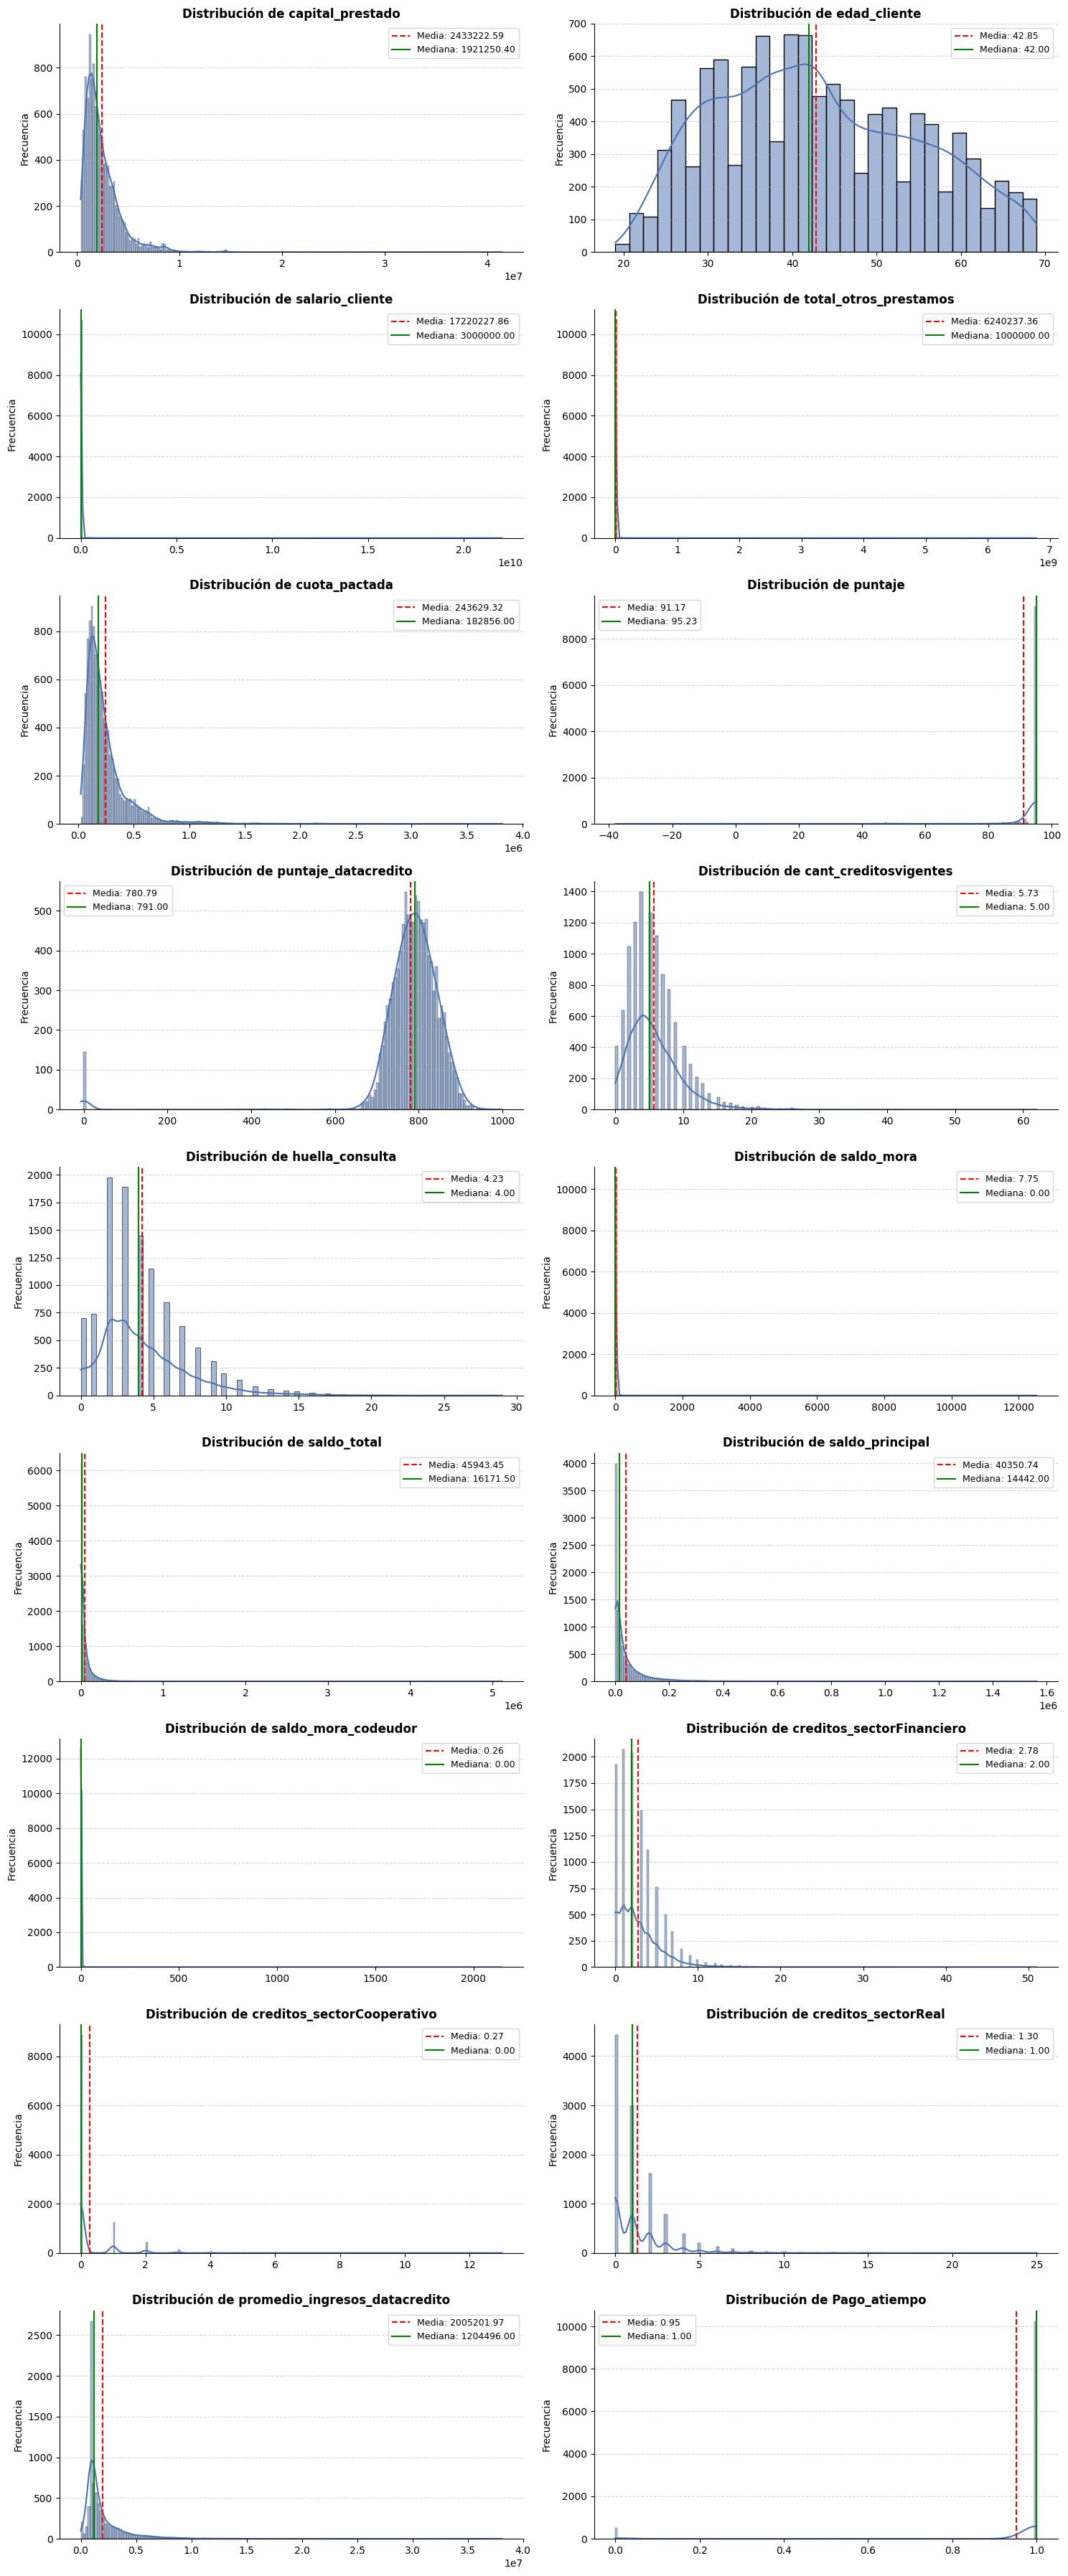

In [29]:
import math
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
# 1. Seleccionar columnas numéricas de forma más general (incluye int32, float32, etc.)
num_cols = df.select_dtypes(include=[np.number]).columns

# 2. Configurar cuadrícula dinámica (3 gráficos por fila)
n_cols = 2
n_rows = math.ceil(len(num_cols) / n_cols)

fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 4 * n_rows))
axes = axes.flatten()  # Aplanar para iterar fácilmente

for i, col in enumerate(num_cols):
  data = df[col].dropna()

  # Histograma + curva de densidad (KDE)
  sns.histplot(data, bins='auto', kde=True, ax=axes[i], color='#4C72B0')

  # Líneas de referencia (Media y Mediana)
  mean_val = data.mean()
  median_val = data.median()
  axes[i].axvline(
      mean_val,
      color='red',
      linestyle='--',
      linewidth=1.5,
      label=f'Media: {mean_val:.2f}',
  )
  axes[i].axvline(
      median_val,
      color='green',
      linestyle='-',
      linewidth=1.5,
      label=f'Mediana: {median_val:.2f}',
  )

  # Estética y limpieza
  axes[i].set_title(f'Distribución de {col}', fontsize=12, fontweight='bold')
  axes[i].set_xlabel('')
  axes[i].set_ylabel('Frecuencia')
  axes[i].legend(fontsize=9)
  axes[i].grid(axis='y', linestyle='--', alpha=0.5)
  sns.despine(ax=axes[i])  # Quita bordes superior y derecho

# 3. Ocultar subgráficos vacíos si el número de columnas no es múltiplo de 3
for j in range(i + 1, len(axes)):
  fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

- **Capital Prestado:** Distribución sesgada hacia la derecha con la mayoría de préstamos concentrados en valores bajos. Presencia de outliers sugiere diferentes segmentos de clientes.

- **Edad Cliente:** Distribución normal con ligero sesgo hacia edades mayores. Concentración principal entre 30-50 años, típico de población crediticiamente activa.

- **Salario Cliente** Fuerte concentración en salarios bajos con cola larga hacia valores altos. Patrón típico de distribución de ingresos en población general.

- **Total Otros Préstamos:** Mayoría de clientes sin otros préstamos, con casos aislados de exposiciones múltiples muy altas. Sugiere portfolio principalmente de primeros créditos.

- **Cuota Pactada:** Distribución sesgada hacia la derecha con concentración en cuotas bajas. Distribución similar a capital, con mayoría en valores bajos y pocos extremos altos.

- **Puntaje:** Altamente concentrado en puntajes entre 80-100.

- **Puntaje Datacrédito:** Similar al puntaje anterior con mayor concentración en 800.

- **Cantidad Créditos Vigentes:** Fuerte concentración entre 0 - 10. Pocos clientes con múltiples exposiciones, indicando gestión conservadora de riesgo.

- **Huella Consulta:** Distribucion sesgada hacia la derecha alta concentracion de personas entre 0 - 5.

- **Saldo Mora:** Mayoría de clientes sin mora (valores en cero), con casos aislados de moras significativas.

- **Saldo Total:** Gran variabilidad con mediana muy inferior a la media, confirmando concentración en saldos bajos con outliers extremos.

- **Saldo Principal:** Patrón similar al saldo total.

- **Saldo Mora Codeudor:** Mayoría absoluta en cero, indicando baja utilización de codeudores y/o buen comportamiento de pago conjunto.

- **Créditos Sector Financiero:** Distribución concentrada en valores bajos, con mayoría de clientes teniendo pocos o ningún crédito en sector financiero.

- **Créditos Sector Cooperativo:** Similar al sector financiero, concentración en valores bajos sugiriendo baja penetración del sector cooperativo.

- **Estadísticas Créditos Sector Real:** Baja exposición promedio en sector real, consistente con el perfil de cartera observado.

- **Promedio Ingresos Datacrédito:** Distribución sesgada similar al salario cliente.

### detectar patrones

In [ ]:


# 1. Filtrar numéricas de forma segura
num_cols = df.select_dtypes(include=[np.number]).columns.drop(
    "Pago_atiempo", errors="ignore"
)

# 2. Calcular métricas pasando una lista estándar y transponer (.T)
resumen = (
    df.groupby("Pago_atiempo")[num_cols]
    .agg(["mean", "median", "std", "min", "max"])
    .T
)

# 3. Renombrar las métricas al español
resumen = resumen.rename(
    index={
        "mean": "Media",
        "median": "Mediana",
        "std": "Desvio",
        "min": "Minimo",
        "max": "Maximo",
    },
    level=1,
)

# 4. Mostrar con 2 decimales
print(resumen.round(2))


Pago_atiempo                                     0            1
capital_prestado              Media     2781774.11   2415844.33
                              Mediana   2268000.00   1908000.00
                              Desvio    1942337.70   1904046.04
                              Minimo     408000.00    360000.00
                              Maximo   11808000.00  41444152.80
...                                            ...          ...
promedio_ingresos_datacredito Media     1605742.05   2023499.88
                              Mediana   1052529.00   1211296.00
                              Desvio    1668892.06   2161936.37
                              Minimo      30285.00         0.00
                              Maximo   18727755.00  38106581.00

[85 rows x 2 columns]


## Categóricas

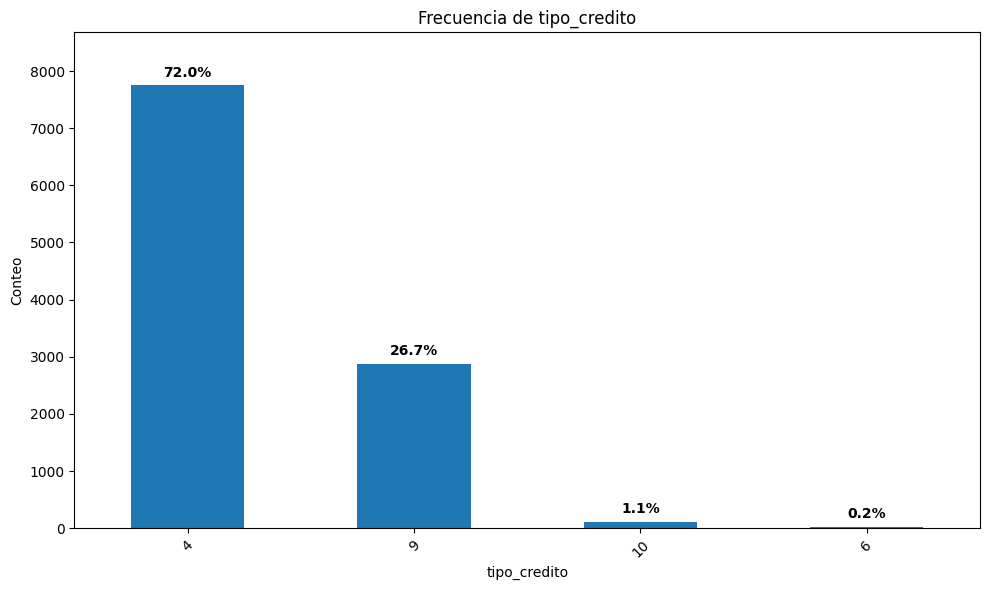

Value counts for tipo_credito:
tipo_credito
4     7747
9     2876
10     116
6       21
Name: count, dtype: int64

--------------------------------------------------


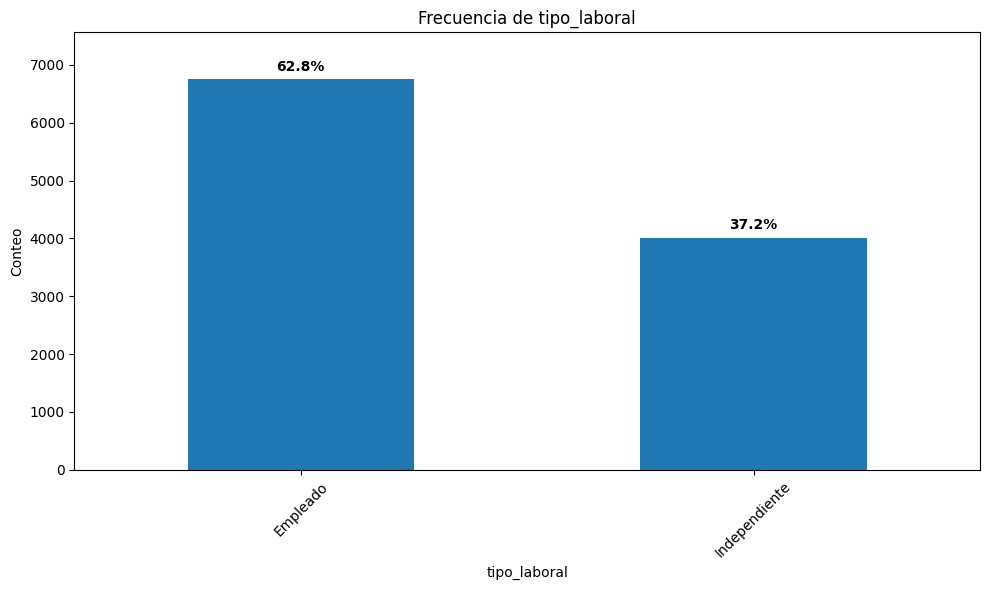

Value counts for tipo_laboral:
tipo_laboral
Empleado         6752
Independiente    4008
Name: count, dtype: int64

--------------------------------------------------


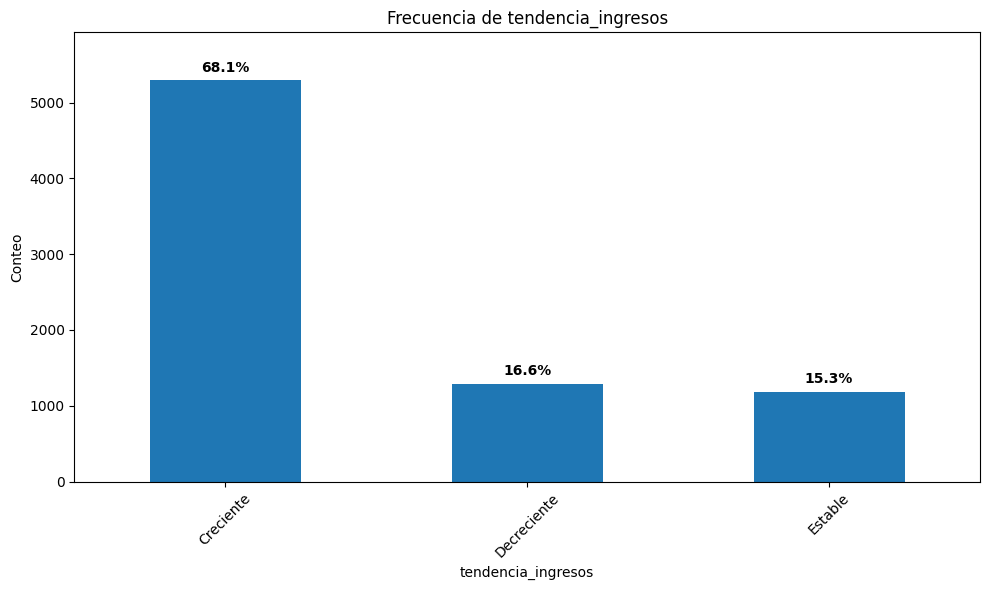

Value counts for tendencia_ingresos:
tendencia_ingresos
Creciente      5293
Decreciente    1291
Estable        1187
Name: count, dtype: int64

--------------------------------------------------


In [36]:
# Buscar columnas categóricas directamente
categorical_cols = df.select_dtypes(include=["object", "category", "bool"]).columns

for col in categorical_cols:
    plt.figure(figsize=(10, 6))
    
    # Guardamos el conteo y creamos el gráfico capturando el eje 'ax'
    conteos = df[col].value_counts()
    ax = conteos.plot(kind="bar")
    
    # Calculamos el total para sacar los porcentajes
    total = len(df[col].dropna()) # Usa len(df) si quieres incluir nulos en el total
    
    # Recorremos cada barra para agregarle el porcentaje arriba
    for barra in ax.patches:
        altura = barra.get_height()
        porcentaje = (altura / total) * 100
        
        ax.annotate(
            f"{porcentaje:.1f}%", # Formato con 1 decimal (ej. 25.4%)
            (barra.get_x() + barra.get_width() / 2, altura), # Posición centrada arriba
            ha="center", 
            va="bottom", 
            fontsize=10,
            fontweight="bold",
            xytext=(0, 4), # Pequeño margen superior de 4 puntos
            textcoords="offset points"
        )
    
    # Damos un poco más de margen arriba en el eje Y para que no se corte el texto
    plt.ylim(0, conteos.max() * 1.12)
    
    plt.title(f"Frecuencia de {col}")
    plt.xlabel(col)
    plt.ylabel("Conteo")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()
    
    print(f"Value counts for {col}:\n{conteos}\n")
    print("-" * 50)

- **Tendencia ingresos** Fuerte desbalance con una categoría dominante representando ~80% de los casos.

- **Tipo credito**
Existe una categoría claramente dominante (probablemente consumo o libre inversión).
Las demás categorías aparecen en proporciones mucho menores.
Esto podría generar desbalance en las clases y requerir técnicas de balanceo o agrupación.

- **Tipo laboral**
Mayoría de clientes son empleados, mientras que los independientes representan un grupo menor.
Podría ser relevante porque los independientes suelen tener mayor probabilidad de incumplimiento.

histograma comparativo de densidad con contorno escalonado

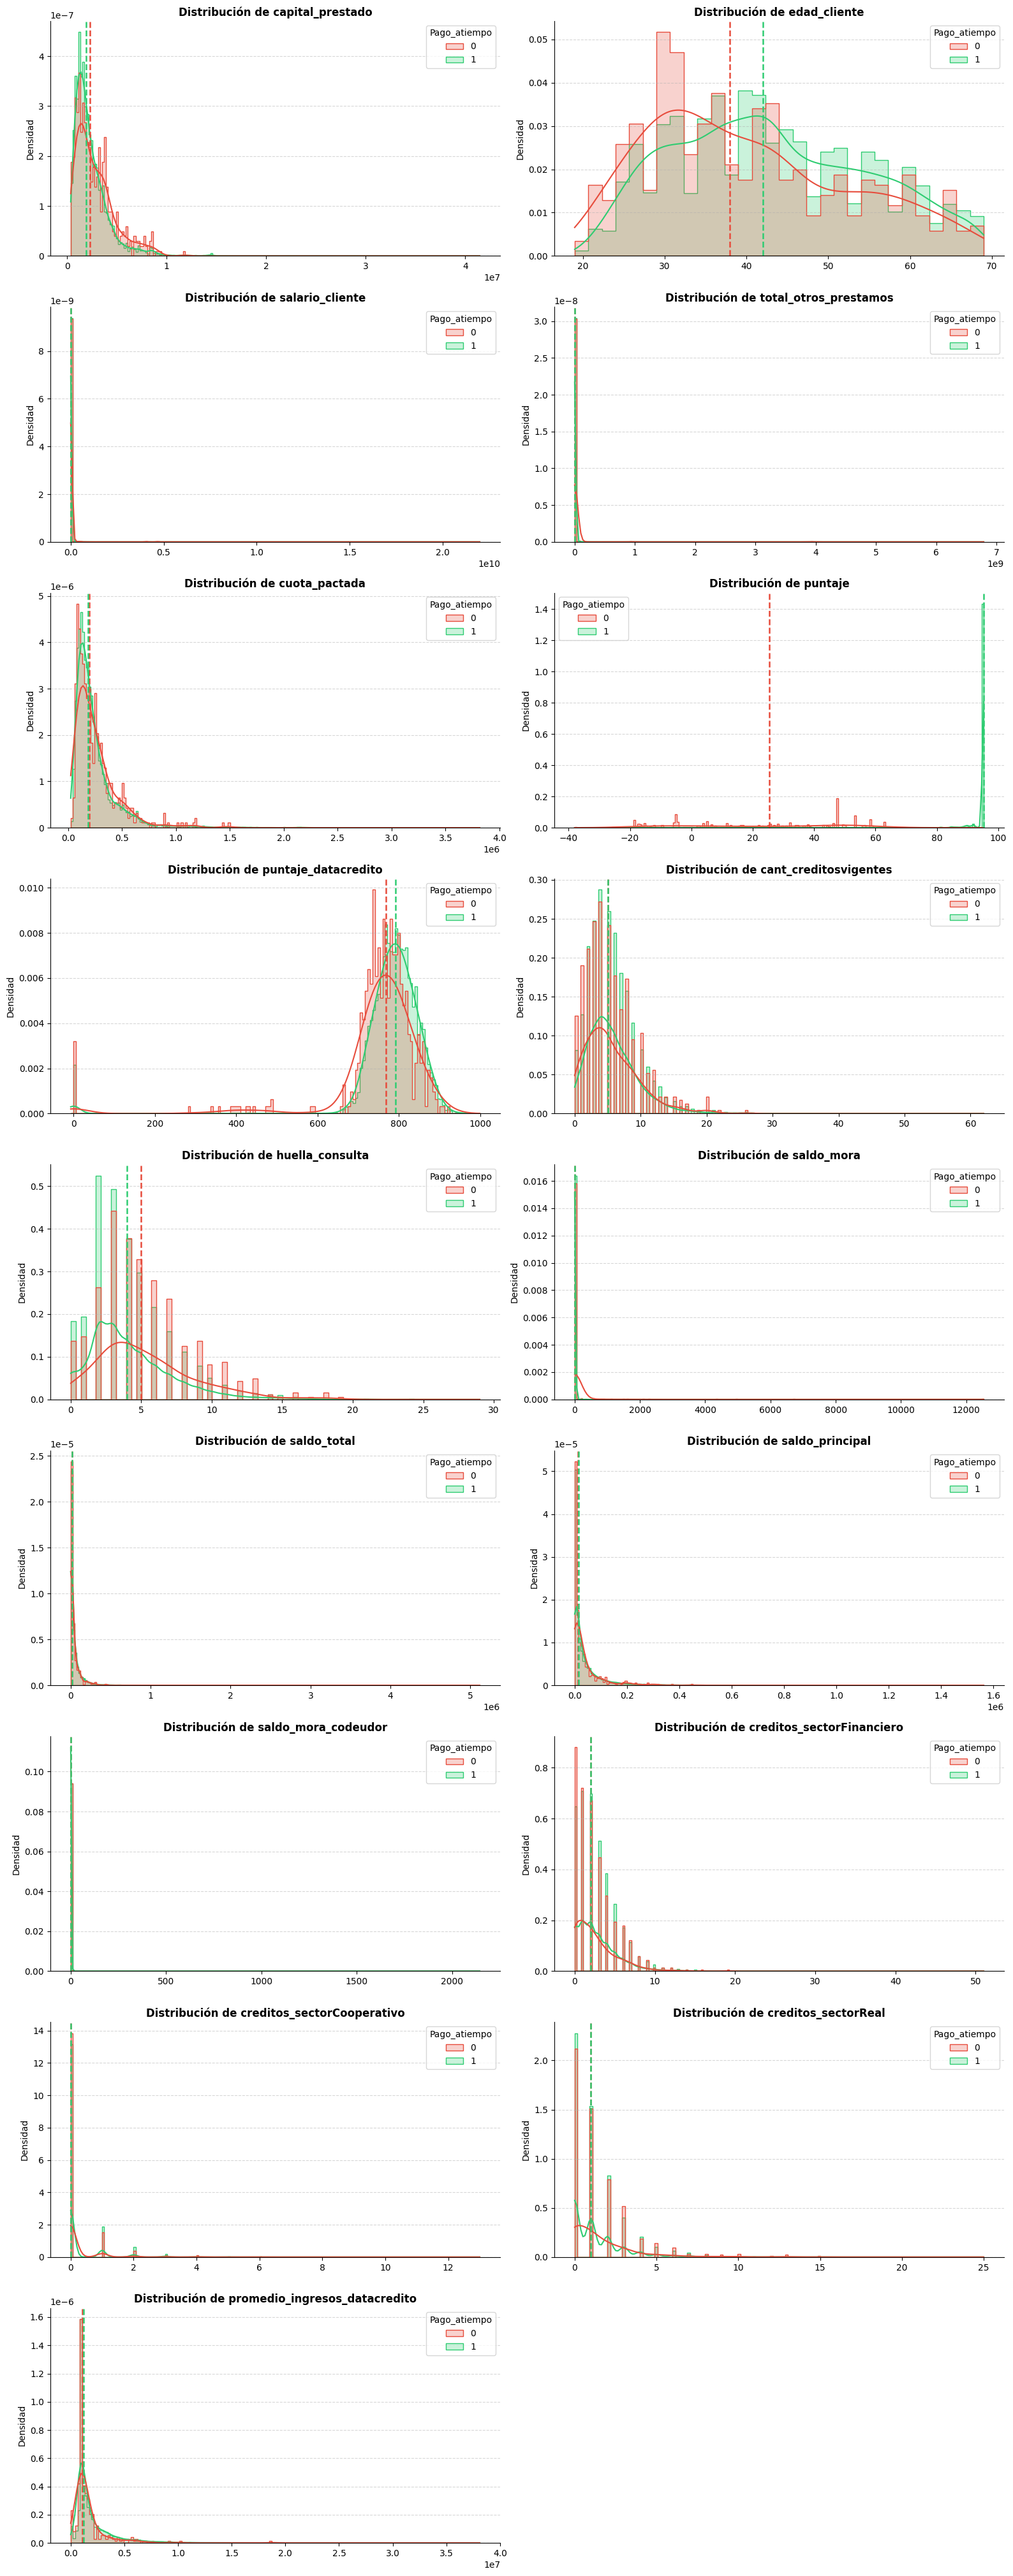

In [39]:
import math
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

# 1. Filtrar numéricas de forma segura (incluye int32/float32 y evita error si Pago_atiempo no es numérica)
num_cols = df.select_dtypes(include=[np.number]).columns.drop(
    "Pago_atiempo", errors="ignore"
)

# 2. Configurar cuadrícula dinámica (3 gráficos por fila)
n_cols = 2
n_rows = math.ceil(len(num_cols) / n_cols)

fig, axes = plt.subplots(n_rows, n_cols, figsize=(16, 4.5 * n_rows))
axes = axes.flatten()

# Paleta de alto contraste (ej. Rojo para 0/No, Verde/Azul para 1/Sí)
paleta = ["#E74C3C", "#2ECC71"]

for i, col in enumerate(num_cols):
  # Histograma tipo step + curva KDE suave para ver mejor la forma
  sns.histplot(
      data=df,
      x=col,
      hue="Pago_atiempo",
      element="step",
      stat="density",
      common_norm=False,
      kde=True,
      palette=paleta,
      alpha=0.25,
      ax=axes[i],
  )

  # Trazar líneas verticales con la mediana de cada grupo
  grupos = sorted(df["Pago_atiempo"].dropna().unique())
  for idx, grupo in enumerate(grupos):
    mediana = df[df["Pago_atiempo"] == grupo][col].median()
    axes[i].axvline(
        mediana,
        color=paleta[idx % len(paleta)],
        linestyle="--",
        linewidth=1.8,
    )

  # Estética y limpieza
  axes[i].set_title(
      f"Distribución de {col}", fontsize=12, fontweight="bold"
  )
  axes[i].set_xlabel("")
  axes[i].set_ylabel("Densidad")
  axes[i].grid(axis="y", linestyle="--", alpha=0.5)
  sns.despine(ax=axes[i])

# 3. Eliminar subgráficos vacíos si sobran espacios en la cuadrícula
for j in range(i + 1, len(axes)):
  fig.delaxes(axes[j])

plt.tight_layout()
plt.show()


Capital Prestado vs Pago a Tiempo:

Los clientes que no pagan a tiempo tienden a tener préstamos de montos más altos. La distribución muestra mayor dispersión en el grupo de no pagadores, sugiriendo que montos elevados aumentan el riesgo de incumplimiento.
Plazo Meses vs Pago a Tiempo:

Los buenos pagadores se concentran en plazos medios (12-36 meses), mientras que los malos pagadores muestran mayor variabilidad. Plazos muy largos parecen asociarse con mayor riesgo de incumplimiento.
Edad Cliente vs Pago a Tiempo:

Diferencia notable: clientes que pagan a tiempo tienden a ser mayores (concentración 35-50 años). Los más jóvenes muestran mayor propensión al incumplimiento, confirmando edad como factor de riesgo.
Salario Cliente vs Pago a Tiempo:

Los buenos pagadores muestran distribución más concentrada en ingresos medios-altos. Los malos pagadores tienen mayor dispersión, incluyendo casos de ingresos altos que no pagan, sugiriendo otros factores de riesgo.
Total Otros Préstamos vs Pago a Tiempo:

Clara diferenciación: malos pagadores tienen significativamente más exposición en otros préstamos. Alta correlación entre sobreendeudamiento y riesgo de incumplimiento.
Cuota Pactada vs Pago a Tiempo:

Los buenos pagadores se concentran en cuotas bajas-medias. Cuotas muy altas se asocian con mayor riesgo, probablemente por compromiso excesivo de la capacidad de pago.
Puntaje vs Pago a Tiempo:

Diferenciación muy clara: buenos pagadores tienen scores superiores (600-800), malos pagadores concentrados en scores bajos (300-500). Confirma el poder predictivo del scoring crediticio.
Puntaje Datacrédito vs Pago a Tiempo:

Similar al puntaje anterior pero con diferenciación aún más marcada. Los buenos pagadores están claramente en rangos altos (700+), validando la calidad de esta fuente de información.
Cantidad Créditos Vigentes vs Pago a Tiempo:

Los buenos pagadores tienden a tener 1-2 créditos, mientras que los malos pagadores muestran mayor dispersión incluyendo casos con muchos créditos vigentes. Sobreendeudamiento como indicador de riesgo.
Huella Consulta vs Pago a Tiempo:

Los malos pagadores tienen más consultas crediticias, sugiriendo búsqueda desesperada de crédito. Los buenos pagadores muestran comportamiento más estable con pocas consultas.

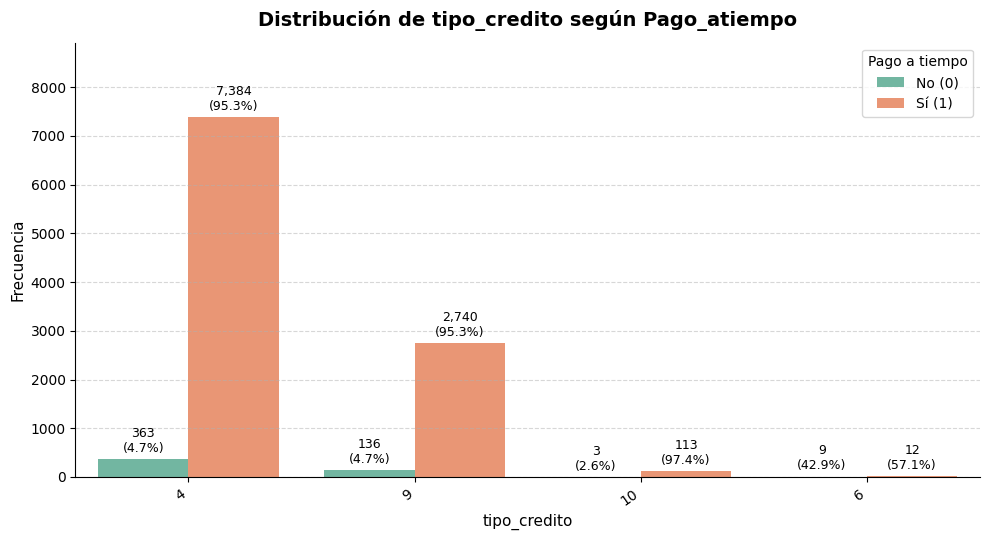

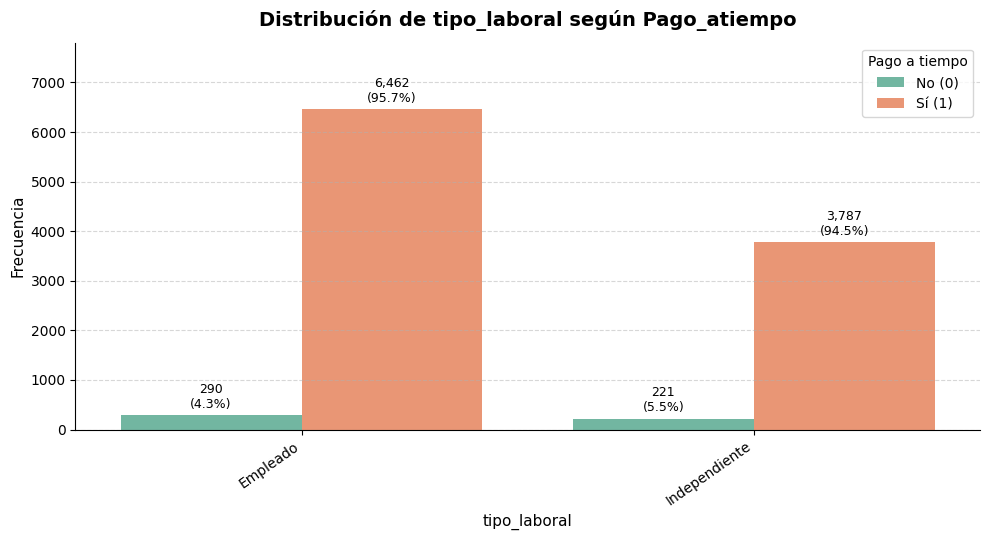

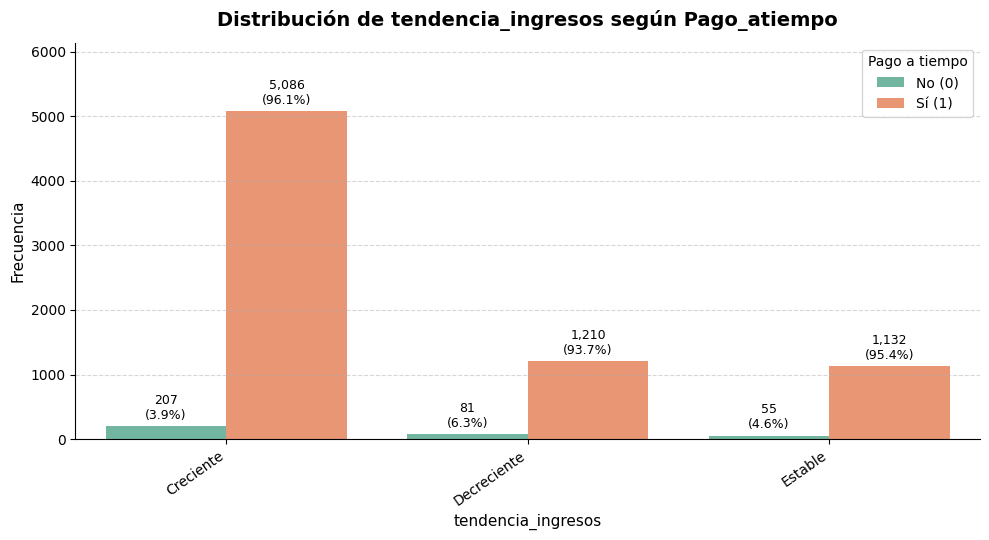

In [42]:

# Filtrar columnas categóricas (incluyendo booleanas por si acaso)
cat_cols = df.select_dtypes(include=['object', 'category', 'bool']).columns

for col in cat_cols:
    # Evitar columnas con demasiadas categorías (ej. IDs o fechas) que harían ilegible el gráfico
    if df[col].nunique() > 15:
        print(f"⚠️ Se omitió '{col}' por tener demasiadas categorías ({df[col].nunique()}).")
        continue

    plt.figure(figsize=(10, 5.5))
    
    # Ordenar las categorías de mayor a menor frecuencia
    orden = df[col].value_counts().index
    
    ax = sns.countplot(
        data=df, 
        x=col, 
        hue="Pago_atiempo", 
        order=orden,
        palette="Set2"
    )
    
    # Calcular el total por cada categoría del eje X para sacar los porcentajes
    totales_por_categoria = df[col].value_counts().reindex(orden).values
    
    # Agregar etiqueta con "Conteo (%)" encima de cada barra
    for container in ax.containers:
        etiquetas = [
            f"{int(barra.get_height()):,}\n({barra.get_height() / total * 100:.1f}%)" 
            if barra.get_height() > 0 else ""
            for barra, total in zip(container, totales_por_categoria)
        ]
        ax.bar_label(container, labels=etiquetas, fontsize=9, padding=3)

    # CORRECCIÓN: Tomamos solo el límite superior con [1] antes de multiplicar
    plt.ylim(0, ax.get_ylim()[1] * 1.15)
    
    plt.title(f"Distribución de {col} según Pago_atiempo", fontsize=14, fontweight="bold", pad=12)
    plt.xlabel(col, fontsize=11)
    plt.ylabel("Frecuencia", fontsize=11)
    plt.xticks(rotation=35, ha="right")
    plt.legend(title="Pago a tiempo", labels=["No (0)", "Sí (1)"])
    plt.grid(axis="y", linestyle="--", alpha=0.5)
    
    sns.despine()
    plt.tight_layout()
    plt.show()


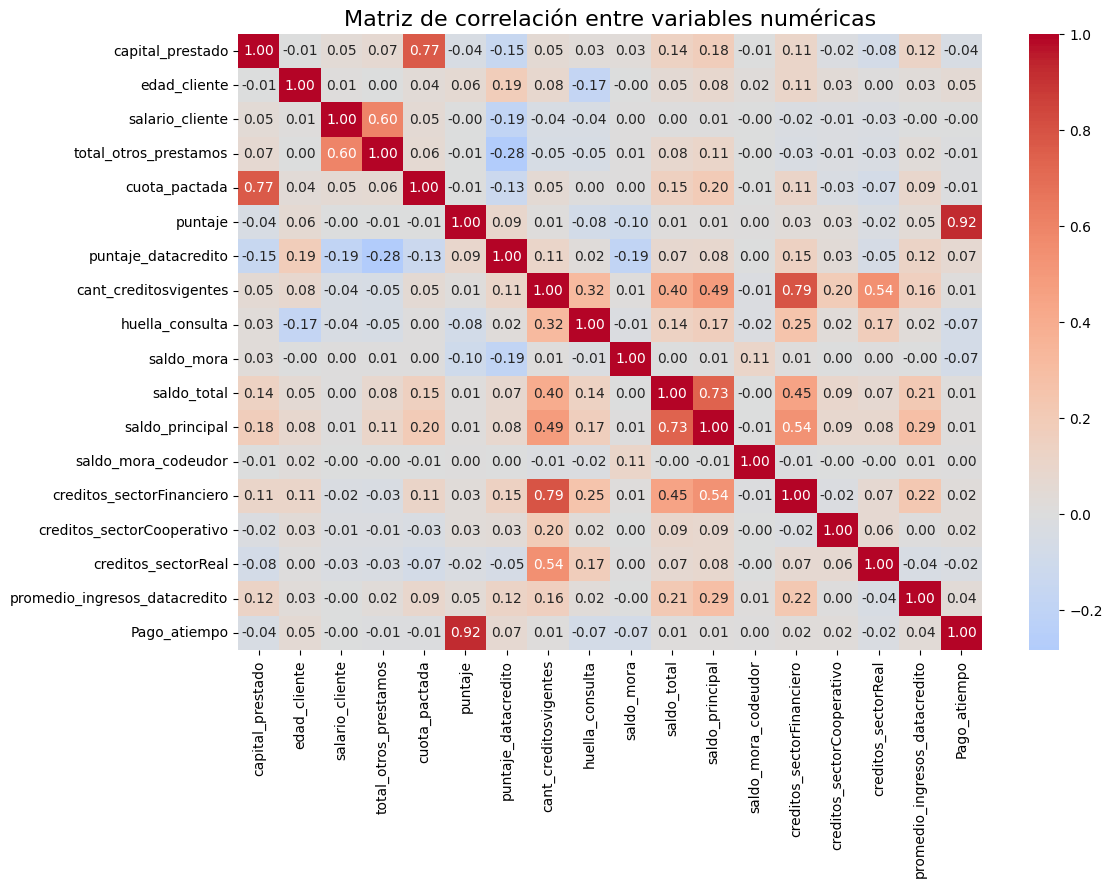

In [43]:
plt.figure(figsize=(12,8))
corr = df.corr(numeric_only=True)
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Matriz de correlación entre variables numéricas", fontsize=16)
plt.show()


Correlaciones más fuertes (≥ 0.7):

Correlaciones positivas muy altas

Pago_atiempo con puntaje (0.92) - Los clientes que pagan a tiempo tienen mejores puntajes crediticios

creditos_sectorFinanciero con cant_creditosvigentes (0.79) - Más créditos en sector financiero se asocia con más créditos vigentes

saldo_total con saldo_principal (0.73) - Relación directa entre saldos totales y principales

Correlaciones moderadas (0.4-0.7):

salario_cliente con total_otros_prestamos (0.60) - Salarios más altos se asocian con más préstamos

creditos_sectorReal con cant_creditosvigentes (0.54) - Créditos en sector real correlacionan con cantidad de créditos vigentes

saldo_principal con creditos_sectorFinanciero (0.54)

Correlaciones negativas notables:

edad_cliente con puntaje_datacredito (-0.38) - Los clientes mayores tienden a tener puntajes más bajos

cuota_pactada con puntaje_datacredito (-0.28) - Cuotas más altas se asocian con puntajes más bajos

huellas_consulta con edad_cliente (-0.24) - Los clientes mayores tienen menos consultas de crédito

In [49]:
# 1. Calcular los porcentajes por fila (tasa de pago/impago dentro de cada grupo)
tabla_pct = (
    pd.crosstab(
        [df["tipo_laboral"], df["tipo_credito"]],
        df["Pago_atiempo"],
        normalize="index",
    )
    * 100
)

# 2. Agregar el conteo total de clientes y su porcentaje respecto al total de la cartera
conteos = pd.crosstab(
    [df["tipo_laboral"], df["tipo_credito"]], df["Pago_atiempo"]
).sum(axis=1)
tabla_pct["Total_Casos"] = conteos
tabla_pct["%_Cartera"] = (conteos / conteos.sum()) * 100

# 3. Definir formato visual: símbolo '%' para tasas y peso, y separador de miles para el conteo
cols_tasas = tabla_pct.columns[:-2]  # Las columnas de Pago_atiempo (ej. 0 y 1)
formato = {col: "{:.2f}%" for col in cols_tasas}
formato["Total_Casos"] = "{:,.0f}"
formato["%_Cartera"] = "{:.2f}%"

# 4. Aplicar mapa de calor solo a las tasas y formatear toda la tabla
display(
    tabla_pct.style.format(formato).background_gradient(
        subset=cols_tasas, cmap="RdYlGn"
    )
)


In [51]:

# 1. Calcular los porcentajes por fila
tabla_pct = (
    pd.crosstab(
        [df["tipo_laboral"], df["tipo_credito"]],
        df["Pago_atiempo"],
        normalize="index",
    )
    * 100
)

# 2. Renombrar columnas (0 -> No Cumple, 1 -> Cumple) y los nombres del índice
tabla_pct = tabla_pct.rename(columns={0: "No Cumple", 1: "Cumple"})
tabla_pct.index.names = ["Condición Laboral", "Tipo de Crédito"]

# 3. Agregar conteo total y porcentaje sobre el total de la cartera
conteos = pd.crosstab(
    [df["tipo_laboral"], df["tipo_credito"]], df["Pago_atiempo"]
).sum(axis=1)
tabla_pct["Total Casos"] = conteos
tabla_pct["% Cartera"] = (conteos / conteos.sum()) * 100

# 4. Configurar formatos visuales
formato = {
    "No Cumple": "{:.2f}%",
    "Cumple": "{:.2f}%",
    "Total Casos": "{:,.0f}",
    "% Cartera": "{:.2f}%",
}

# 5. Estilizar: resaltar índices en negrita y aplicar escala de color inversa (rojo = alta mora, verde = alto cumplimiento)
estilo = (
    tabla_pct.style.format(formato)
    .background_gradient(
        subset=["No Cumple"], cmap="Reds"
    )  # Más rojo cuanto más incumple
    .background_gradient(
        subset=["Cumple"], cmap="Greens"
    )  # Más verde cuanto más cumple
    .set_table_styles([
        # Destacar los nombres de Empleado / Independiente en negrita y con fondo gris suave
        {
            "selector": "th.row_heading.level0",
            "props": [
                ("font-weight", "bold"),
                ("font-size", "13px"),
                ("background-color", "#f0f2f6"),
                ("color", "#1f2937"),
                ("border-top", "2px solid #9ca3af"),
            ],
        },
        # Añadir línea divisoria sutil al cambiar de grupo laboral
        {
            "selector": "td",
            "props": [("border-bottom", "1px solid #e5e7eb")],
        },
    ])
)

display(estilo)


## 💳 Análisis de Riesgo: Tipo de Crédito vs. Condición Laboral

### 1. Desempeño por Producto

| Tipo de Crédito | Empleados (Mora) | Independientes (Mora) | Brecha (*Gap*) Relativa | Nivel de Riesgo y Observaciones |
| :--- | :---: | :---: | :---: | :--- |
| **Tipo 10**<br>*(Mejor desempeño)* | **2.67%** | **2.44%** | **-8.6%** *(Indep. mejor)* | 🟢 **Óptimo:** Independientes superan levemente a empleados. Posible producto diseñado a medida. |
| **Tipo 4**<br>*(Estándar)* | **4.14%** | **5.71%** | **+37.9%** *(Indep. peor)* | 🟡 **Moderado:** Brecha consistente con el comportamiento histórico general de la cartera. |
| **Tipo 9**<br>*(Estándar)* | **4.36%** | **5.19%** | **+19.0%** *(Indep. peor)* | 🟢 **Bueno:** Diferencia acotada; ambos segmentos mantienen un desempeño saludable. |
| **Tipo 6**<br>*(Foco crítico)* | **42.86%** | *Sin registros* | N/A | 🔴 **Crítico:** Producto de mayor mora. Ausencia de independientes sugiere bloqueo previo por política. |

---

### 2. Hallazgos Clave del Portafolio

> * **Patrón general consistente:** En casi toda la línea de productos los trabajadores independientes presentan mayor probabilidad de incumplimiento, validando la necesidad de segmentación por perfil laboral.
> * **La excepción del Tipo 10:** Es el producto más sano de la cartera y el único donde los independientes muestran menor mora (`2.44%` vs `2.67%`), lo que indica un buen ajuste entre el producto y el flujo de caja de este segmento.
> * **Alerta en Tipo 6:** Con un **42.86%** de incumplimiento en empleados, este producto requiere revisión urgente de sus criterios de originación (aun cuando ya excluye a independientes).

---

### 3. Implicaciones para *Pricing* y Políticas de Riesgo

* 💰 **Diferenciación de tasas (*Pricing* basado en riesgo):** Se justifica aplicar un *spread* (tasa ligeramente superior) para independientes en productos tradicionales como **Tipo 4** y **Tipo 9**.
* 🤝 **Estrategia comercial en Tipo 10:** Mantener condiciones competitivas e iguales (o preferenciales) para independientes, usando este producto como gancho de adquisición de bajo riesgo.
* 🛑 **Auditoría en Tipo 6:** Evaluar si el **42.86%** de mora responde a una muestra muy pequeña o a una falla estructural en la evaluación crediticia de empleados para ese producto.


In [52]:


# 1. Crear la tabla porcentual
tabla_pct = (
    pd.crosstab(
        [df["tendencia_ingresos"], df["tipo_laboral"]],
        df["Pago_atiempo"],
        normalize="index",
    )
    * 100
)

# 2. Renombrar columnas (0 -> No Cumple, 1 -> Cumple) e índices
tabla_pct = tabla_pct.rename(columns={0: "No Cumple", 1: "Cumple"})
tabla_pct.index.names = ["Tendencia de Ingresos", "Condición Laboral"]

# 3. Agregar el volumen total de casos y el peso porcentual sobre toda la cartera
conteos = pd.crosstab(
    [df["tendencia_ingresos"], df["tipo_laboral"]], df["Pago_atiempo"]
).sum(axis=1)
tabla_pct["Total Casos"] = conteos
tabla_pct["% Cartera"] = (conteos / conteos.sum()) * 100

# 4. Ordenar de mayor a menor porcentaje de incumplimiento
tabla_pct = tabla_pct.sort_values(by="No Cumple", ascending=False)

# 5. Configurar formatos y colores diferenciados para Empleado vs Independiente
formato = {
    "No Cumple": "{:.2f}%",
    "Cumple": "{:.2f}%",
    "Total Casos": "{:,.0f}",
    "% Cartera": "{:.2f}%",
}


def resaltar_laboral(val):
  if str(val).lower().startswith("emp"):
    return "background-color: #e0f2fe; color: #0369a1; font-weight: bold;"  # Azul suave para Empleado
  elif str(val).lower().startswith("ind"):
    return "background-color: #fef3c7; color: #b45309; font-weight: bold;"  # Ámbar suave para Independiente
  return ""


# Como Condición Laboral es parte del índice, lo pasamos temporalmente a columna para aplicarle color por celda
tabla_visual = tabla_pct.reset_index()

estilo = (
    tabla_visual.style.format(formato)
    .hide(axis="index")  # Oculta el índice numérico 0, 1, 2...
    .map(
        resaltar_laboral, subset=["Condición Laboral"]
    )  # Pinta Empleado vs Independiente
    .background_gradient(subset=["No Cumple"], cmap="Reds")
    .background_gradient(subset=["Cumple"], cmap="Greens")
    .set_properties(
        subset=["Tendencia de Ingresos"], **{"font-weight": "bold"}
    )
)

display(estilo)


Tendencia de Ingresos,Condición Laboral,No Cumple,Cumple,Total Casos,% Cartera
Decreciente,Independiente,7.34%,92.66%,354,4.56%
Decreciente,Empleado,5.87%,94.13%,937,12.06%
Creciente,Independiente,4.82%,95.18%,"1,451",18.67%
Estable,Independiente,4.81%,95.19%,541,6.96%
Estable,Empleado,4.49%,95.51%,646,8.31%
Creciente,Empleado,3.57%,96.43%,"3,842",49.44%


## 📊 Análisis de Riesgo: Tendencia de Ingresos vs. Tipo Laboral

### 1. Desempeño por Segmento

| Tendencia de Ingresos | Tipo Laboral | Tasa de Incumplimiento | Calificación | Brecha (*Gap*) y Observaciones |
| :--- | :--- | :---: | :---: | :--- |
| **📈 Crecientes**<br>*(Mejor desempeño)* | Empleado | **3.56%** | 🟢 Excelente | Independientes tienen **+35%** más riesgo relativo, pero ambos perfiles son saludables. |
| | Independiente | **4.82%** | 🟢 Bueno | |
| **➡️ Estables**<br>*(Desempeño intermedio)* | Empleado | **4.89%** | 🟡 Aceptable | **Dato clave:** Independientes muestran un riesgo ligeramente menor que empleados. |
| | Independiente | **4.80%** | 🟡 Aceptable | |
| **📉 Decrecientes**<br>*(Mayor riesgo)* | Empleado | **5.87%** | 🟠 Regular | Independientes tienen **+25%** más riesgo relativo; ambos segmentos requieren alerta. |
| | Independiente | **7.34%** | 🔴 Alto riesgo | |

---

### 2. Jerarquía de Riesgo (De menor a mayor mora)

1. 🟢 **Riesgo Mínimo:** Ingresos crecientes + Empleado (**3.56%**)
2. 🟢 **Riesgo Bajo:** Ingresos crecientes + Independiente (**4.82%**)
3. 🟡 **Riesgo Medio:** Ingresos estables — ambos perfiles (**~4.80% - 4.89%**)
4. 🟠 **Riesgo Alto:** Ingresos decrecientes + Empleado (**5.87%**)
5. 🔴 **Riesgo Crítico:** Ingresos decrecientes + Independiente (**7.34%**)

---

### 3. Hallazgos Contraintuitivos

> * **Paridad en estabilidad:** Cuando los ingresos son estables, los trabajadores independientes presentan una mora levemente inferior a los empleados (`4.80%` vs `4.89%`).
> * **Variable dominante:** La **tendencia de ingresos** tiene mayor poder predictivo sobre el incumplimiento que la condición laboral por sí sola.

---

### 4. Recomendaciones para Políticas de Crédito

* ✅ **Promover / Aprobar:** Priorizar ofertas comerciales a cualquier perfil con **ingresos crecientes**, sin penalizar fuertemente al independiente.
* 🔍 **Reevaluar:** Los perfiles con **ingresos estables** requieren variables adicionales (ej. antigüedad o nivel de endeudamiento) para discriminar mejor el riesgo.
* ⛔ **Restringir / Encarecer:** Aplicar filtros más estrictos, tasas ajustadas por riesgo o menor monto máximo a **independientes con ingresos decrecientes**.
